## EDS-220 HWK-4 Task 2: False Color


### Importing Libraries and Data

In [ ]:
# Import packages
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import rioxarray as rio

# Import fire perimeter data
eaton = gpd.read_file('data/Eaton_Perimeter_20250121/Eaton_Perimeter_20250121.shp')
palisades = gpd.read_file('data/Palisades_Perimieter_20250121/Palisades_Perimieter_20250121.shp')

### Preliminary Fire Data Exploration:

In [2]:
# Check CRS and projection of GeoDataFrames
print('Eaton CRS:', eaton.crs)
print('Palisades CRS:', palisades.crs)

print('Eaton GeoDataFrame is geographic:', eaton.crs.is_geographic)
print('Palisades GeoDataFrame is geographic:', palisades.crs.is_geographic)




Eaton CRS: EPSG:4269
Palisades CRS: EPSG:4269
Eaton GeoDataFrame is geographic: True
Palisades GeoDataFrame is geographic: True


## 2. Fire Perimeter Data Exploration



The CRSs' of the Eaton perimeter data and the Palisades perimeter dataframes match (EPSG:4269). Additionally, the projections are both geographic. 


### Preliminary Landsat Data Exploration

In [3]:
# Import landsat 8 data using xr.open_dataset()
# Check landsat variables, dimensions, and coordinates
with xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc') as landsat:
    print(landsat.info())

xarray.Dataset {
dimensions:
	y = 1418 ;
	x = 2742 ;

variables:
	float64 y(y) ;
		y:units = metre ;
		y:resolution = -30.0 ;
		y:crs = EPSG:32611 ;
		y:axis = Y ;
		y:long_name = y coordinate of projection ;
		y:standard_name = projection_y_coordinate ;
	float64 x(x) ;
		x:units = metre ;
		x:resolution = 30.0 ;
		x:crs = EPSG:32611 ;
		x:axis = X ;
		x:long_name = x coordinate of projection ;
		x:standard_name = projection_x_coordinate ;
	datetime64[ns] time() ;
	float32 red(y, x) ;
		red:grid_mapping = spatial_ref ;
	float32 green(y, x) ;
		green:grid_mapping = spatial_ref ;
	float32 blue(y, x) ;
		blue:grid_mapping = spatial_ref ;
	float32 nir08(y, x) ;
		nir08:grid_mapping = spatial_ref ;
	float32 swir22(y, x) ;
		swir22:grid_mapping = spatial_ref ;
	int64 spatial_ref() ;
		spatial_ref:crs_wkt = PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["

## 3. NetCDF data import and exploration

The dimensions of the landsat 8 data are 1418 by 2742. The x and y coordinates are both measured in meters. Notable variables include x & y coordinates, time (datetime64), red, green, blue, nir, and swir bands. 


## 4. Restoring geospatial information

In [4]:
# Check CRS of landsat 8 data
print(landsat.rio.crs)
# 'None'

None


In [5]:
# Recheck CRS using .crs_wkt
print(landsat.spatial_ref.crs_wkt)
# CRS is EPSG 32611

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


In [ ]:
# Use rio.write_crs() to manually set CRS of landsat
landsat.rio.write_crs(32611, inplace = True)

# Verify CRS of landsat dataframe
print(landsat.rio.crs)

EPSG:32611


## 5. True Color Image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


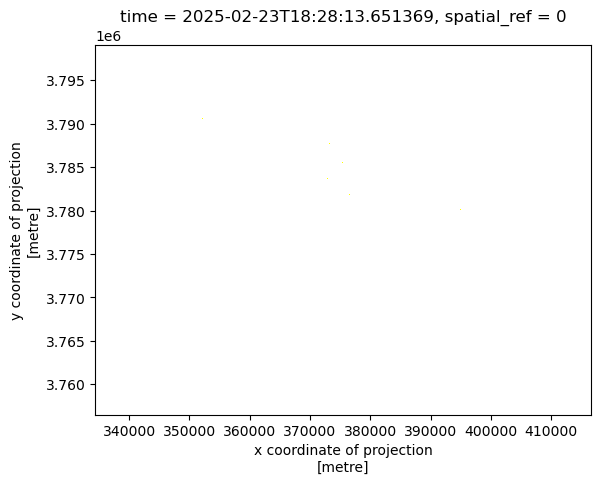

In [ ]:
# a. Plot landsat rgb 
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()

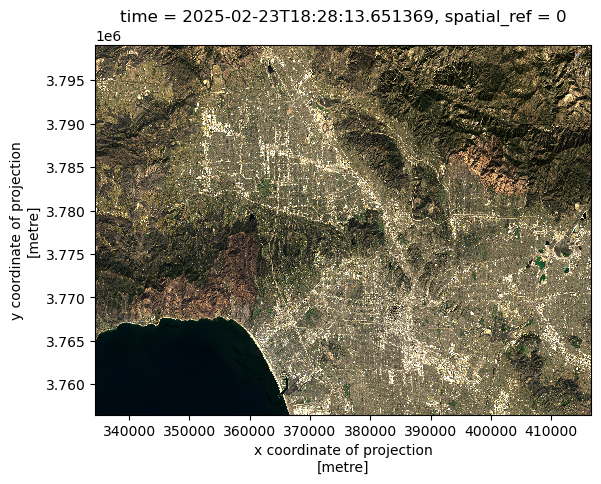

In [39]:
# b. Select red, green, and blue bands 
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust = True)

In [ ]:
# c. To resolve the other warning, identify which bands have nan values. 
# d. Use the .fillna() method for xarray.Dataset to replace any nan values in the Landsat data with zero 
landsat = landsat.fillna(0)

Text(0.5, 1.0, 'Palisade and Eaton Fire Imagery (2025)')

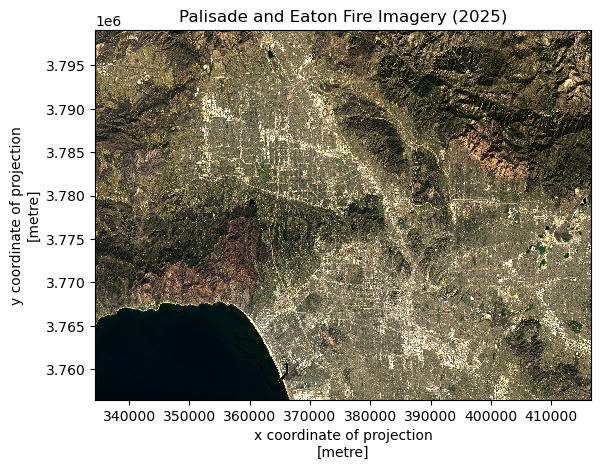

In [ ]:
# e. Create a new true color image that gets plotted without warnings 
fig, ax = plt.subplots()

landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(ax = ax, robust = True)

plt.title('Palisade and Eaton Fire Imagery (2025)')

f. In a markdown cell write a brief explanantion comparing the outputs for parts (a) and (e)
The output for part (a) included values outside the range of the 2nd and 98th percentile which includes the most extreme values. The output for part (e) sets the vmin and vmax, by default, to the 2nd and 98th percentile values which excludes the extreme values. We then filled the NA values with 0 which allowed us to plot the landsat values properly this time. 



## 6. False Color Image 
Without creating any new variables, create a false color, image, by plotting the shortwave infrared (swirr22), near-infrared, and red variables (in that order). 

Text(0.5, 1.0, 'False Color Image of Eaton and Palisades Fires (2025)')

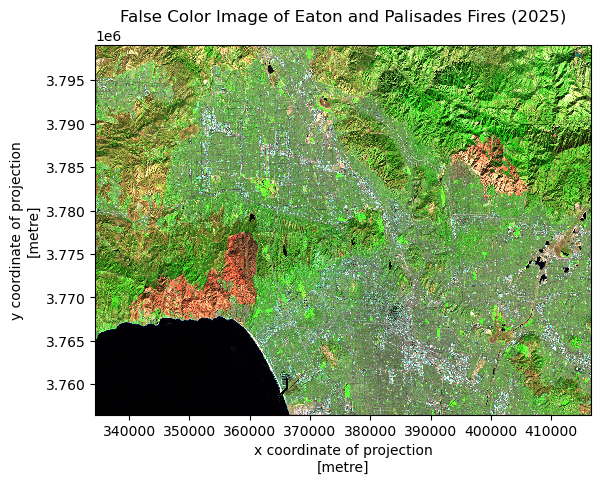

In [44]:
# Plot false color image using shortwave infrared, near-infrared, and red 
fig, ax = plt.subplots()

landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(ax = ax, robust = True)

plt.title('False Color Image of Eaton and Palisades Fires (2025)')

## 7. Map
a. Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire perimeters. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which. 

b. Write a figure description for the map including a brief explanantion of how false color imagery is being used. 

In [48]:
# Changing CRSs' of Eaton and Palisades to match landsat data (EPSG:32611)
eaton = eaton.to_crs(landsat.rio.crs)

palisades = palisades.to_crs(landsat.rio.crs)

assert eaton.crs == landsat.rio.crs, 'CRS do not match!'
assert palisades.crs == landsat.rio.crs, 'CRS do not match!'

In [50]:
# Concatonate both Eaton and Palisades fire perimeters 
both_fires = pd.concat([eaton, palisades])

# Assert both_fires match CRS of landsat data
assert both_fires.crs == landsat.rio.crs

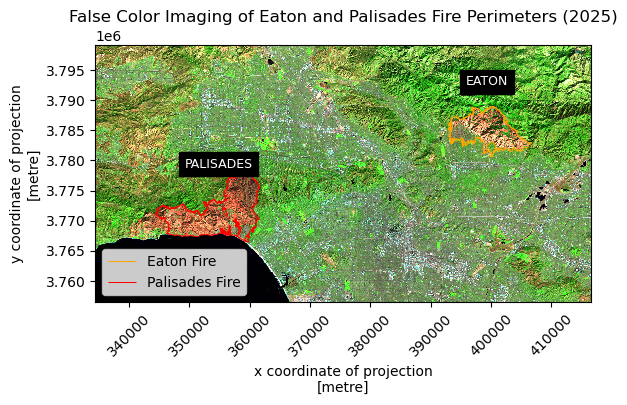

In [67]:
# Initialize map
fig, ax = plt.subplots()

# Plot shortwave, near-infrared, and red 
landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(ax = ax, robust = True)

# Rotate x-axis values
plt.xticks(rotation = 45)

# Add title
plt.title('False Color Imaging of Eaton and Palisades Fire Perimeters (2025)')

# Create boundary for Eaton and Palisades
eaton.boundary.plot(ax = ax, color = 'orange', label = 'Eaton Fire', linewidth = 0.75)
palisades.boundary.plot(ax = ax, color = 'red', label = 'Palisades Fire', linewidth = 0.75)

# For loop for names labels 
for n, name in zip(range(0, 2), both_fires['FIRE_NAME']):
    ax.text(both_fires.centroid.iloc[n].x, 
            both_fires.centroid.iloc[n].y + 7500, 
            name, 
            fontsize = 9, 
            color = 'white',
            ha = 'center',
            backgroundcolor = 'black')
    
# Position legend in the bottom left
plt.legend(loc = 'lower left')



### Final Map Reflection

The false color imagery is of the Palisades and Eaton fire as captured by Landsat 8 on February 23, 2025. The false color imagery is displayed using shortwave infrared (swir22) in the red channel, near-infrared (nir08) in the green channel, and red in the blue channel. The Eaton fire perimeter is indicated using orange and the Eaton fire is indicated using red. The colors within them are reflecting the shortwave infrared which is causing them to stand out more than the surrounding green vegetation which is reflected by the near-infrared.